pandas introduction

In [1]:
import pandas as pd

# Creiamo un dizionario con dati di esempio
dati = {
    'Campione': [1, 2, 3, 4],
    'Feature_A': [10.5, 12.0, 9.8, 11.2],
    'Feature_B': [50, 42, 55, 48],
    'Target_Classe': ['OK', 'KO', 'OK', 'OK']
}

# Creazione del DataFrame
df = pd.DataFrame(dati)

# Visualizzazione della tabella
print("Il nostro primo DataFrame in Pandas:")
display(df)
# Estraiamo la colonna dei valori della Feature_A
feature_a = df['Feature_A']
print(feature_a)

# Filtriamo solo le righe dove Target_Classe è uguale a 'OK'
df_ok = df[df['Target_Classe'] == 'OK']
print("Statistiche descrittive della Feature_A per i campioni con Target_Classe 'OK':")
print('------- display(df_ok) ------------')
display(df_ok)
print('-------- print(df_ok) -----------')
print(df_ok)
print('-------- print(df_ok[\'Feature_A\'].describe()) -----------')
print(df_ok['Feature_A'].describe())
# Mostra conteggio, media, deviazione standard, min, max e percentili
print('-------- print(df.describe()) -----------')
print(df.describe())



Il nostro primo DataFrame in Pandas:


,Campione,Feature_A,Feature_B,Target_Classe
0,1,10.5,50,OK
1,2,12.0,42,KO
2,3,9.8,55,OK
3,4,11.2,48,OK


0    10.5
1    12.0
2     9.8
3    11.2
Name: Feature_A, dtype: float64
Statistiche descrittive della Feature_A per i campioni con Target_Classe 'OK':
------- display(df_ok) ------------


,Campione,Feature_A,Feature_B,Target_Classe
0,1,10.5,50,OK
2,3,9.8,55,OK
3,4,11.2,48,OK


-------- print(df_ok) -----------
   Campione  Feature_A  Feature_B Target_Classe
0         1       10.5         50            OK
2         3        9.8         55            OK
3         4       11.2         48            OK
-------- print(df_ok['Feature_A'].describe()) -----------
count     3.00
mean     10.50
std       0.70
min       9.80
25%      10.15
50%      10.50
75%      10.85
max      11.20
Name: Feature_A, dtype: float64
-------- print(df.describe()) -----------
       Campione  Feature_A  Feature_B
count  4.000000   4.000000   4.000000
mean   2.500000  10.875000  48.750000
std    1.290994   0.942956   5.377422
min    1.000000   9.800000  42.000000
25%    1.750000  10.325000  46.500000
50%    2.500000  10.850000  49.000000
75%    3.250000  11.400000  51.250000
max    4.000000  12.000000  55.000000


pandas cvs management

In [3]:
import pandas as pd

# Carichiamo il file CSV presente nella cartella del progetto
df_csv = pd.read_csv('dati.csv', sep=';')

# Visualizziamo le prime n righe del dataset per un controllo rapido
print("Prime n righe del dataset:")
display(df_csv.head(3))

print(df_csv.iloc[1:2, 1:2],'\n')
# header non viene considerato come riga del DataFrame, 
# quindi la riga 1 corrisponde alla seconda riga del file CSV ed 
# ha indice 0 nel DataFrame.
x = df_csv.iloc[0:1, 0:1]
print(x,'\n')
print(x.values[0][0],'\n')

y = df_csv.iloc[1, 1]
print(y,'\n')


# Vediamo informazioni generali sulla struttura (tipi di dati e valori nulli)
print("Informazioni generali sul DataFrame:")
df_csv.info()

Prime n righe del dataset:


,Col1,Col2,Col3
0,1.50000,2.0,3.1089
1,4.20178,5.5,6.0000
2,5.00000,6.0,7.2000


   Col2
1   5.5 

   Col1
0   1.5 

1.5 

5.5 

Informazioni generali sul DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Col1    3 non-null      float64
 1   Col2    3 non-null      float64
 2   Col3    3 non-null      float64
dtypes: float64(3)
memory usage: 204.0 bytes


add new row

In [2]:
import pandas as pd

# Carichiamo il file CSV presente nella cartella del progetto
df_csv = pd.read_csv('dati.csv', sep=';')

# 1. Definiamo la nuova riga come un piccolo DataFrame (con le stesse colonne)
nuova_riga = pd.DataFrame([{'Col1': -2, 'Col2': 1.5, 'Col3': 30}])

# 2. Concateniamo il vecchio DataFrame con la nuova riga
# ignore_index=True serve a rinumerare correttamente le righe in sequenza (0, 1, 2, 3...)
df_csv = pd.concat([df_csv, nuova_riga] if 'nuova_riga' in locals() else [df_csv, nuova_riga], ignore_index=True)

# Semplificato:
df_csv = pd.concat([df_csv, nuova_riga*2], ignore_index=True)

# 3. Vediamo il risultato aggiornato
display(df_csv.tail())  # .tail() mostra le ultime righe

df_csv.to_csv('dati2.csv', sep=';', index=False)
df_csv.to_csv('dati3.csv', sep=';', index=True)

print("File salvato con successo!")

,Col1,Col2,Col3
0,1.50000,2.0,3.1089
1,4.20178,5.5,6.0000
2,5.00000,6.0,7.2000
3,-2.00000,1.5,30.0000
4,-4.00000,3.0,60.0000


File salvato con successo!


OOP for program with CVS and pandas

In [ ]:
import pandas as pd

class DatasetManager:
    """Classe orientata agli oggetti per caricare, modificare e salvare dataset."""
    
    def __init__(self, filepath, sep=';'):
        self.filepath = filepath
        self.sep = sep
        self.df = None
        
    def load_data(self):
        """Carica il file CSV in un DataFrame."""
        self.df = pd.read_csv(self.filepath, sep=self.sep)
        print(f"Dataset '{self.filepath}' caricato correttamente.")
        
    def add_row(self, row_data):
        """Aggiunge una nuova riga passando un dizionario."""
        nuova_riga = pd.DataFrame([row_data])
        self.df = pd.concat([self.df, nuova_riga], ignore_index=True)
        print("Nuova riga aggiunta con successo.")
        
    def show_tail(self, n=5):
        """Mostra le ultime righe del DataFrame."""
        display(self.df.tail(n))
        
    def save_data(self, output_path, include_index=False):
        """Salva il DataFrame modificato su un nuovo file CSV."""
        self.df.to_csv(output_path, sep=self.sep, index=include_index)
        print(f"File salvato con successo come '{output_path}'.")

# ==========================================
# Utilizzo pratico della classe
# ==========================================

# 1. Istanziamo l'oggetto
manager = DatasetManager('dati.csv', sep=';')

# 2. Carichiamo i dati
manager.load_data()

# 3. Aggiungiamo una riga usando un dizionario
manager.add_row({'Col1': -2.0, 'Col2': 1.5, 'Col3': 30.0})

# 4. Visualizziamo la fine del DataFrame
manager.show_tail()

# 5. Salviamo il nuovo file
manager.save_data('dati_oop_output.csv', include_index=False)

Dataset 'dati.csv' caricato correttamente.
Nuova riga aggiunta con successo.


,Col1,Col2,Col3
0,1.50000,2.0,3.1089
1,4.20178,5.5,6.0000
2,5.00000,6.0,7.2000
3,-2.00000,1.5,30.0000


File salvato con successo come 'dati_oop_output.csv'.


use panda in a OOP program

In [2]:
import pandas as pd

class DataAnalyzer:
    """
    Classe didattica per l'analisi esplorativa dei dati (EDA).
    Incapsula un DataFrame di Pandas e fornisce metodi strutturati 
    per la visualizzazione e il filtraggio pulito dei dati.
    """
    
    def __init__(self, dataframe):
        """
        Il costruttore (__init__) viene eseguito quando istanziamo la classe.
        Salva il DataFrame come attributo dell'oggetto (self.df), rendendolo
        accessibile a tutti gli altri metodi della classe.
        """
        self.df = dataframe
        
    def show_summary(self):
        """
        Metodo per stampare una panoramica generale del dataset:
        - Mostra la tabella completa interattiva (tramite display)
        - Calcola le statistiche descrittive di base (conteggio, media, std, min, max, percentili)
          per tutte le colonne numeriche.
        """
        print("--- [PANORAMICA] Il nostro primo DataFrame in Pandas ---")
        display(self.df)
        
        print("\n--- [STATISTICHE GENERALI] print(self.df.describe()) ---")
        # .describe() ignora automaticamente le colonne di tipo stringa/oggetto 
        # e analizza solo quelle numeriche.
        print(self.df.describe())
        
    def filter_and_analyze(self, column_name, condition_value, target_feature):
        """
        Filtra il DataFrame applicando una condizione booleana e restituisce
        un sotto-insieme (subset) di dati su cui calcolare statistiche mirate.
        """
        print(f"\n--- [FILTRAGGIO] Selezioniamo le righe dove '{column_name}' == '{condition_value}' ---")
        
        # 1. Filtraggio condizionale (Boolean Indexing):
        # self.df[column_name] == condition_value crea una serie di True/False.
        # Passandola dentro self.df[...] estraiamo solo le righe che soddisfano la condizione.
        df_filtered = self.df[self.df[column_name] == condition_value]
        
        # 2. Mostriamo il DataFrame filtrato
        display(df_filtered)
        
        print(f"--- [STATISTICHE MIRATE] Analizziamo la colonna '{target_feature}' sul filtrato ---")
        
        # 3. Estraiamo la singola colonna (Series) e calcoliamo le statistiche descrittive
        target_description = df_filtered[target_feature].describe()
        print(target_description)
        
        # Restituiamo il DataFrame filtrato nel caso volessimo usarlo per altri calcoli
        return df_filtered


# =====================================================================
# BLOCCO PRINCIPALE (Main) - Utilizzo pratico della classe nel Notebook
# =====================================================================

# 1. Creiamo un dizionario di dati grezzi di esempio
dati = {
    'Campione': [1, 2, 3, 4],
    'Feature_A': [10.5, 12.0, 9.8, 11.2],
    'Feature_B': [50, 42, 55, 48],
    'Target_Classe': ['OK', 'KO', 'OK', 'OK']
}

# 2. Convertiamo il dizionario in un DataFrame di Pandas
df_principale = pd.DataFrame(dati)

# 3. Istanziamo l'oggetto 'analyzer' passando il DataFrame al costruttore
analyzer = DataAnalyzer(df_principale)

# 4. Richiamiamo il primo metodo per la panoramica generale
analyzer.show_summary()

# 5. Richiamiamo il metodo di filtraggio avanzato per isolare solo i campioni 'OK'
df_ok = analyzer.filter_and_analyze(
    column_name='Target_Classe', 
    condition_value='OK', 
    target_feature='Feature_A'
)

--- [PANORAMICA] Il nostro primo DataFrame in Pandas ---


,Campione,Feature_A,Feature_B,Target_Classe
0,1,10.5,50,OK
1,2,12.0,42,KO
2,3,9.8,55,OK
3,4,11.2,48,OK



--- [STATISTICHE GENERALI] print(self.df.describe()) ---
       Campione  Feature_A  Feature_B
count  4.000000   4.000000   4.000000
mean   2.500000  10.875000  48.750000
std    1.290994   0.942956   5.377422
min    1.000000   9.800000  42.000000
25%    1.750000  10.325000  46.500000
50%    2.500000  10.850000  49.000000
75%    3.250000  11.400000  51.250000
max    4.000000  12.000000  55.000000

--- [FILTRAGGIO] Selezioniamo le righe dove 'Target_Classe' == 'OK' ---


,Campione,Feature_A,Feature_B,Target_Classe
0,1,10.5,50,OK
2,3,9.8,55,OK
3,4,11.2,48,OK


--- [STATISTICHE MIRATE] Analizziamo la colonna 'Feature_A' sul filtrato ---
count     3.00
mean     10.50
std       0.70
min       9.80
25%      10.15
50%      10.50
75%      10.85
max      11.20
Name: Feature_A, dtype: float64


Programma che rappresenta seno e coseno

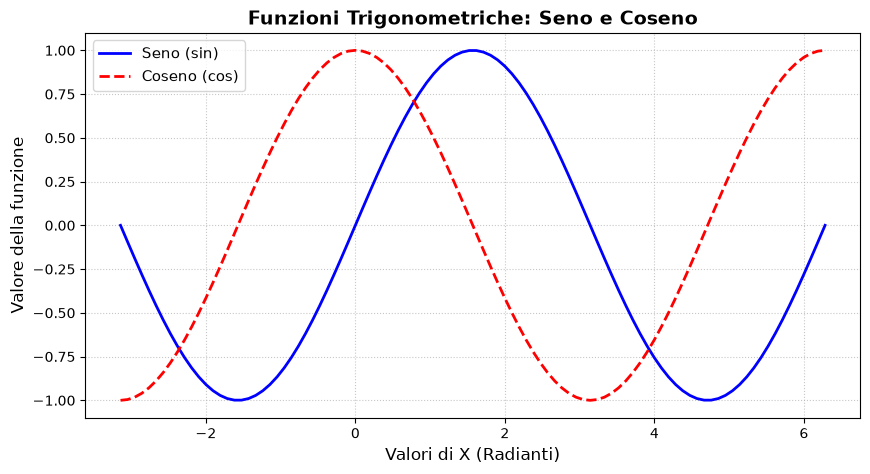

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generazione dei dati con NumPy
# Creiamo un array di 100 punti che vanno da 0 a 2*pi greco (un ciclo completo)
x = np.linspace(-np.pi, 2 * np.pi, 100)

# Calcoliamo i valori corrispondenti per il seno e il coseno
y_seno = np.sin(x)
y_coseno = np.cos(x)

# 2. Configurazione e creazione del grafico con Matplotlib
plt.figure(figsize=(10, 5)) # Definisce le dimensioni della finestra del grafico (larghezza, altezza)

# Tracciamo la curva del Seno
plt.plot(x, y_seno, label='Seno (sin)', color='blue', linewidth=2, linestyle='-')

# Tracciamo la curva del Coseno
plt.plot(x, y_coseno, label='Coseno (cos)', color='red', linewidth=2, linestyle='--')

# 3. Personalizzazione del grafico (Elementi essenziali)
plt.title('Funzioni Trigonometriche: Seno e Coseno', fontsize=14, fontweight='bold')
plt.xlabel('Valori di X (Radianti)', fontsize=12)
plt.ylabel('Valore della funzione', fontsize=12)

# Aggiungiamo una griglia per facilitare la lettura visiva
plt.grid(True, linestyle=':', alpha=0.7)

# Mostriamo la legenda per distinguere le curve
plt.legend(fontsize=11)

# 4. Visualizzazione finale
plt.show()

--- [PANORAMICA] DataFrame principale ---


,Campione,Feature_A,Feature_B,Target_Classe
0,1,10.5,50,OK
1,2,12.0,42,KO
2,3,9.8,55,OK
3,4,11.2,48,OK
4,5,14.5,60,KO
5,6,8.1,39,OK
6,7,10.9,52,OK
7,8,13.4,47,KO



--- [STATISTICHE] ---
       Campione  Feature_A  Feature_B
count   8.00000   8.000000   8.000000
mean    4.50000  11.300000  49.125000
std     2.44949   2.015653   6.770472
min     1.00000   8.100000  39.000000
25%     2.75000  10.325000  45.750000
50%     4.50000  11.050000  49.000000
75%     6.25000  12.350000  52.750000
max     8.00000  14.500000  60.000000

--- [GRAFICO] Analisi visiva della feature: 'Feature_A' ---


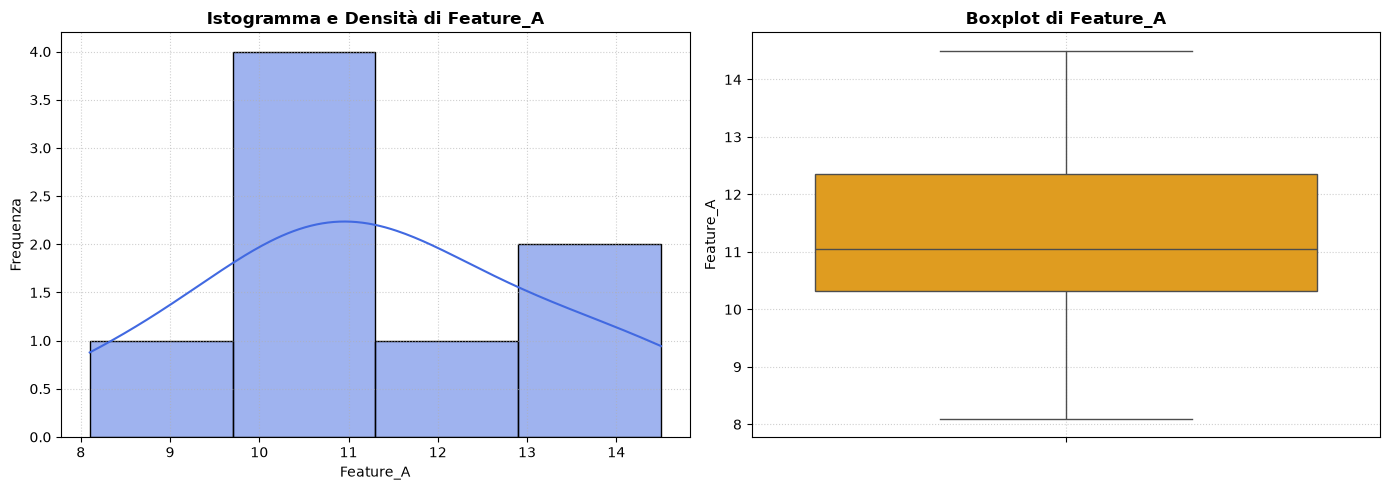

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

class DataAnalyzer:
    """
    Classe didattica avanzata per l'analisi esplorativa dei dati (EDA) 
    e la visualizzazione grafica integrata.
    """
    
    def __init__(self, dataframe):
        """Costruttore: riceve il DataFrame e lo salva come attributo dell'oggetto."""
        self.df = dataframe
        
    def show_summary(self):
        """Stampa la panoramica generale e le statistiche descrittive."""
        print("--- [PANORAMICA] DataFrame principale ---")
        display(self.df)
        print("\n--- [STATISTICHE] ---")
        print(self.df.describe())
        
    def plot_feature_distribution(self, target_feature):
        """
        Metodo OOP per generare grafici statistici (Istogramma + Boxplot) 
        di una specifica colonna numerica usando Seaborn e Matplotlib.
        """
        print(f"\n--- [GRAFICO] Analisi visiva della feature: '{target_feature}' ---")
        
        # Creiamo una figura con 2 sotto-grafici affiancati (1 riga, 2 colonne)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # 1. Grafico a sinistra: Istogramma con curva di densità (KDE)
        sns.histplot(self.df[target_feature], kde=True, ax=axes[0], color='royalblue')
        axes[0].set_title(f'Istogramma e Densità di {target_feature}', fontsize=12, fontweight='bold')
        axes[0].set_xlabel(target_feature, fontsize=10)
        axes[0].set_ylabel('Frequenza', fontsize=10)
        axes[0].grid(True, linestyle=':', alpha=0.6)
        
        # 2. Grafico a destra: Boxplot (ottimo per vedere mediana, quartili e outlier)
        sns.boxplot(y=self.df[target_feature], ax=axes[1], color='orange')
        axes[1].set_title(f'Boxplot di {target_feature}', fontsize=12, fontweight='bold')
        axes[1].set_ylabel(target_feature, fontsize=10)
        axes[1].grid(True, linestyle=':', alpha=0.6)
        
        # Ottimizza lo spaziamento tra i grafici per evitare sovrapposizioni
        plt.tight_layout()
        
        # Mostra il risultato grafico nel notebook
        plt.show()


# =====================================================================
# BLOCCO PRINCIPALE (Main) - Testiamo la nuova classe con i grafici
# =====================================================================

# 1. Creiamo un dataset di esempio un po' più ricco
dati = {
    'Campione': [1, 2, 3, 4, 5, 6, 7, 8],
    'Feature_A': [10.5, 12.0, 9.8, 11.2, 14.5, 8.1, 10.9, 13.4],
    'Feature_B': [50, 42, 55, 48, 60, 39, 52, 47],
    'Target_Classe': ['OK', 'KO', 'OK', 'OK', 'KO', 'OK', 'OK', 'KO']
}

# 2. Istanziamo il DataFrame e la classe DataAnalyzer
df_principale = pd.DataFrame(dati)
analyzer = DataAnalyzer(df_principale)

# 3. Stampiamo il sommario testuale
analyzer.show_summary()

# 4. Richiamiamo il nuovo metodo per generare i grafici sulla 'Feature_A'
analyzer.plot_feature_distribution(target_feature='Feature_A')

Concatenazione dataframe, aggiunge righe

In [6]:
import pandas as pd

# Creiamo due dataset di esempio
df1 = pd.DataFrame({
    'ID': [1, 2],
    'Prodotto': ['Mouse', 'Tastiera'],
    'Prezzo': [25, 45]
})

df2 = pd.DataFrame({
    'ID': [3, 4],
    'Prodotto': ['Monitor', 'Cuffie'],
    'Prezzo': [150, 60]
})

# Concateniamo i DataFrame verticalmente (uno sotto l'altro)
# ignore_index=True serve a resettare gli indici (0, 1, 2, 3...)
df_unito = pd.concat([df1, df2], ignore_index=True)

print("--- DataFrame df1 ---")
display(df1)
print("--- DataFrame df2 ---")
display(df2)
print("--- DataFrame Concatenato ---")
display(df_unito)

--- DataFrame df1 ---


,ID,Prodotto,Prezzo
0,1,Mouse,25
1,2,Tastiera,45


--- DataFrame df2 ---


,ID,Prodotto,Prezzo
0,3,Monitor,150
1,4,Cuffie,60


--- DataFrame Concatenato ---


,ID,Prodotto,Prezzo
0,1,Mouse,25
1,2,Tastiera,45
2,3,Monitor,150
3,4,Cuffie,60


Concatenazione dataframe, aggiunge colonne

In [7]:
# Tabella 1: Clienti
clienti = pd.DataFrame({
    'ID_Cliente': [101, 102, 103],
    'Nome': ['Alice', 'Bob', 'Charlie'],
    'Città': ['Roma', 'Milano', 'Napoli']
})

# Tabella 2: Ordini effettuati dai clienti
ordini = pd.DataFrame({
    'ID_Cliente': [101, 102, 101, 104], # Nota: 104 non esiste nella tabella clienti
    'Prodotto': ['Laptop', 'Mouse', 'Tastiera', 'Monitor'],
    'Importo': [1200, 30, 50, 200]
})

# Uniamo basandoci sulla colonna 'ID_Cliente'
df_merged = pd.merge(clienti, ordini, on='ID_Cliente', how='left')

print("--- Merge (Left Join) ---")
display(df_merged)

--- Merge (Left Join) ---


,ID_Cliente,Nome,Città,Prodotto,Importo
0,101,Alice,Roma,Laptop,1200.0
1,101,Alice,Roma,Tastiera,50.0
2,102,Bob,Milano,Mouse,30.0
3,103,Charlie,Napoli,NaN,NaN


gestione dataframe con OOP

Dataset 'gennaio' aggiunto correttamente.
Dataset 'febbraio' aggiunto correttamente.
Concatenazione completata! Creato il nuovo dataset 'trimestre_gen_feb'.

--- Visualizzazione Dataset: 'trimestre_gen_feb' ---


,ID,Prodotto,Prezzo
0,1,Mouse,25
1,2,Tastiera,45
2,3,Monitor,150
3,4,Cuffie,60


Dataset 'clienti' aggiunto correttamente.
Dataset 'ordini' aggiunto correttamente.
Merge (left) completato! Creato il nuovo dataset 'clienti_con_ordini'.

--- Visualizzazione Dataset: 'clienti_con_ordini' ---


,ID_Cliente,Nome,Città,Prodotto,Importo
0,101,Alice,Roma,Laptop,1200.0
1,101,Alice,Roma,Tastiera,50.0
2,102,Bob,Milano,Mouse,30.0
3,103,Charlie,Napoli,NaN,NaN


In [9]:
import pandas as pd  # Importa la libreria Pandas attribuendole l'alias 'pd' per gestire i DataFrame

class DatasetMerger:
    """
    Classe orientata agli oggetti per gestire la concatenazione 
    e l'unione (merge) di più dataset con Pandas.
    """
    
    def __init__(self):
        # Inizializza un attributo d'istanza chiamato 'datasets' come dizionario vuoto.
        # Servirà a memorizzare i DataFrame associandoli a una chiave (il nome).
        self.datasets = {}
        
    def add_dataset(self, name, df):
        """
        Aggiunge un DataFrame al dizionario interno usando un nome come chiave.
        """
        # Salva il DataFrame 'df' nel dizionario 'self.datasets' sotto la chiave 'name'
        self.datasets[name] = df
        
        # Stampa un messaggio di conferma dell'avvenuta aggiunta del dataset
        print(f"Dataset '{name}' aggiunto correttamente.")
        
    def concatenate(self, name1, name2, output_name, axis=0, ignore_index=True):
        """
        Concatena due dataset presenti nell'oggetto (equivalente di pd.concat).
        - axis=0: unione verticale (combina le righe, mantenendo le colonne)
        - axis=1: unione orizzontale (combina le colonne, mantenendo le righe)
        - ignore_index=True: rigenera l'indice numerico da 0 a N nel risultato
        """
        # Verifica se uno dei due nomi dei dataset non è presente nel dizionario interno
        if name1 not in self.datasets or name2 not in self.datasets:
            print("Errore: Uno o entrambi i dataset non esistono.")  # Notifica l'errore se manca un dataset
            return  # Interrompe l'esecuzione del metodo ritornando None
            
        # Recupera il primo DataFrame dal dizionario usando il nome specificato
        df1 = self.datasets[name1]
        
        # Recupera il secondo DataFrame dal dizionario usando il nome specificato
        df2 = self.datasets[name2]
        
        # Esegue la concatenazione nativa di Pandas passando la lista dei due DataFrame, l'asse e il flag ignore_index
        result = pd.concat([df1, df2], axis=axis, ignore_index=ignore_index)
        
        # Salva il nuovo DataFrame concatenato nel dizionario interno con la chiave 'output_name'
        self.datasets[output_name] = result
        
        # Stampa una conferma dell'operazione completata
        print(f"Concatenazione completata! Creato il nuovo dataset '{output_name}'.")
        
        # Restituisce il DataFrame risultante per consentire l'uso diretto se richiesto
        return result
        
    def merge_datasets(self, left_name, right_name, output_name, on_column, how='inner'):
        """
        Unisce due dataset basandosi su una colonna comune (equivalente di pd.merge).
        - left_name: chiave del DataFrame di sinistra
        - right_name: chiave del DataFrame di destra
        - on_column: il nome della colonna comune utilizzata come chiave di unione
        - how: tipo di join ('inner', 'left', 'right', 'outer')
        """
        # Verifica che entrambi i dataset siano caricati nel dizionario interno
        if left_name not in self.datasets or right_name not in self.datasets:
            print("Errore: Uno o entrambi i dataset non esistono.")  # Segnala la mancanza di uno o entrambi i dati
            return  # Esce dal metodo senza eseguire il merge
            
        # Estrae il DataFrame "sinistro" dal dizionario
        df_left = self.datasets[left_name]
        
        # Estrae il DataFrame "destro" dal dizionario
        df_right = self.datasets[right_name]
        
        # Esegue la join/merge dei due DataFrame basandosi sulla colonna 'on_column' e sulla logica specificata in 'how'
        result = pd.merge(df_left, df_right, on=on_column, how=how)
        
        # Memorizza il DataFrame unito all'interno del dizionario sotto la nuova chiave 'output_name'
        self.datasets[output_name] = result
        
        # Stampa a schermo la conferma indicando il tipo di join utilizzato
        print(f"Merge ({how}) completato! Creato il nuovo dataset '{output_name}'.")
        
        # Ritorna il DataFrame generato dal merge
        return result
        
    def show(self, name):
        """
        Mostra a schermo il DataFrame specificato se presente nel dizionario.
        """
        # Controlla se la chiave 'name' esiste nel dizionario 'self.datasets'
        if name in self.datasets:
            # Stampa l'intestazione della visualizzazione
            print(f"\n--- Visualizzazione Dataset: '{name}' ---")
            
            # Utilizza la funzione display() per mostrare il DataFrame formattato (tipico degli ambienti Jupyter/Colab)
            display(self.datasets[name])
        else:
            # Informa l'utente che la chiave richiesta non corrisponde ad alcun dataset caricato
            print(f"Dataset '{name}' non trovato.")


# ==========================================
# ESEMPIO PRATICO DI UTILIZZO DIDATTICO
# ==========================================

# 1. Istanziazione dell'oggetto 'merger' dalla classe 'DatasetMerger'
merger = DatasetMerger()

# --- ESEMPIO 1: CONCATENAZIONE ---
# Creazione del primo DataFrame (vendite di gennaio)
df_gen = pd.DataFrame({'ID': [1, 2], 'Prodotto': ['Mouse', 'Tastiera'], 'Prezzo': [25, 45]})

# Creazione del secondo DataFrame (vendite di febbraio)
df_feb = pd.DataFrame({'ID': [3, 4], 'Prodotto': ['Monitor', 'Cuffie'], 'Prezzo': [150, 60]})

# Registrazione dei due DataFrame nell'istanza 'merger'
merger.add_dataset('gennaio', df_gen)
merger.add_dataset('febbraio', df_feb)

# Esecuzione della concatenazione verticale
merger.concatenate('gennaio', 'febbraio', output_name='trimestre_gen_feb', ignore_index=True)

# Visualizzazione del risultato finale concatenato
merger.show('trimestre_gen_feb')


# --- ESEMPIO 2: MERGE / JOIN ---
# Creazione della tabella clienti
clienti = pd.DataFrame({
    'ID_Cliente': [101, 102, 103],
    'Nome': ['Alice', 'Bob', 'Charlie'],
    'Città': ['Roma', 'Milano', 'Napoli']
})

# Creazione della tabella ordini
ordini = pd.DataFrame({
    'ID_Cliente': [101, 102, 101, 104],
    'Prodotto': ['Laptop', 'Mouse', 'Tastiera', 'Monitor'],
    'Importo': [1200, 30, 50, 200]
})

# Registrazione dei due DataFrame nell'istanza 'merger'
merger.add_dataset('clienti', clienti)
merger.add_dataset('ordini', ordini)

# Esecuzione del Merge di tipo Left Join sulla colonna 'ID_Cliente'
merger.merge_datasets(
    left_name='clienti', 
    right_name='ordini', 
    output_name='clienti_con_ordini', 
    on_column='ID_Cliente', 
    how='left'
)

# Visualizzazione del risultato finale del merge
merger.show('clienti_con_ordini')

Dataset 'gennaio' aggiunto correttamente.
Dataset 'febbraio' aggiunto correttamente.
Concatenazione completata! Creato il nuovo dataset 'trimestre_gen_feb'.

--- Visualizzazione Dataset: 'trimestre_gen_feb' ---


,ID,Prodotto,Prezzo
0,1,Mouse,25
1,2,Tastiera,45
2,3,Monitor,150
3,4,Cuffie,60


Dataset 'clienti' aggiunto correttamente.
Dataset 'ordini' aggiunto correttamente.
Merge (left) completato! Creato il nuovo dataset 'clienti_con_ordini'.

--- Visualizzazione Dataset: 'clienti_con_ordini' ---


,ID_Cliente,Nome,Città,Prodotto,Importo
0,101,Alice,Roma,Laptop,1200.0
1,101,Alice,Roma,Tastiera,50.0
2,102,Bob,Milano,Mouse,30.0
3,103,Charlie,Napoli,NaN,NaN


matplotlib

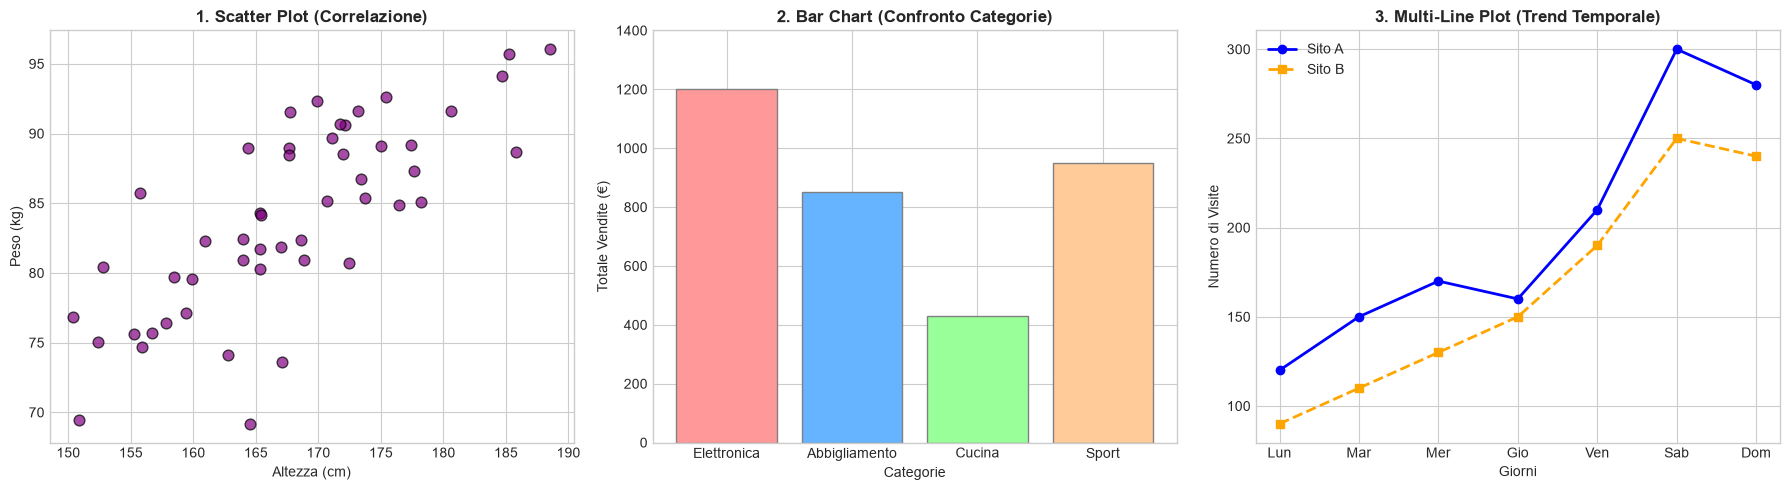

In [10]:
import matplotlib.pyplot as plt  # Importa il modulo di plotting di Matplotlib
import numpy as np               # Importa NumPy per generare dati numerici di supporto

# Configurazione dello stile globale dei grafici (opzionale, rende i grafici più moderni)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Crea una figura con una griglia di 1 riga e 3 colonne di sottografici (subplots)
# figsize=(18, 5) definisce le dimensioni complessive della finestra del grafico in pollici
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# ==========================================
# 1. SCATTER PLOT (Relazione tra due variabili)
# ==========================================
# Generiamo dati casuali fittizi per simulare, ad esempio, Altezza e Peso di un campione
np.random.seed(42)  # Fissa il seme random per riproducibilità dei dati casuali
altezza = np.random.normal(170, 10, 50)  # 50 valori con media 170 e deviazione standard 10
peso = altezza * 0.5 + np.random.normal(0, 5, 50)  # Peso correlato all'altezza con un po' di rumore

# Disegna lo scatter plot sull'asse ax1
ax1.scatter(altezza, peso, color='purple', alpha=0.7, edgecolor='black', s=60)
ax1.set_title("1. Scatter Plot (Correlazione)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Altezza (cm)")
ax1.set_ylabel("Peso (kg)")

# ==========================================
# 2. BAR CHART (Confronto tra categorie)
# ==========================================
# Categorie di prodotti e relative vendite totali
categorie = ['Elettronica', Abbigliamento := 'Abbigliamento', 'Cucina', 'Sport']
vendite = [1200, 850, 430, 950]
colori = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']  # Colori personalizzati per le barre

# Disegna il grafico a barre sull'asse ax2
barche = ax2.bar(categorie, vendite, color=colori, edgecolor='grey', linewidth=1)
ax2.set_title("2. Bar Chart (Confronto Categorie)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Categorie")
ax2.set_ylabel("Totale Vendite (€)")
# Imposta il limite superiore dell'asse Y per dare respiro alle etichette sopra le barre
ax2.set_ylim(0, 1400)

# ==========================================
# 3. MULTI-LINE PLOT (Andamento nel tempo)
# ==========================================
# Asse X: Giorni della settimana
giorni = ['Lun', 'Mar', 'Mer', 'Gio', 'Ven', 'Sab', 'Dom']
# Due serie di dati da confrontare (es. visite a due pagine web differenti)
visite_sito_A = [120, 150, 170, 160, 210, 300, 280]
visite_sito_B = [90, 110, 130, 150, 190, 250, 240]

# Traccia la prima linea per il Sito A
ax3.plot(giorni, visite_sito_A, color='blue', marker='o', linestyle='-', linewidth=2, label='Sito A')
# Traccia la seconda linea per il Sito B
ax3.plot(giorni, visite_sito_B, color='orange', marker='s', linestyle='--', linewidth=2, label='Sito B')

ax3.set_title("3. Multi-Line Plot (Trend Temporale)", fontsize=12, fontweight='bold')
ax3.set_xlabel("Giorni")
ax3.set_ylabel("Numero di Visite")
ax3.legend()  # Mostra la legenda basata sui parametri 'label' definiti sopra
ax3.grid(True)  # Abilita la griglia sul grafico

# ==========================================
# OTTIMIZZAZIONE E MOSTRA FINALE
# ==========================================
# Regola automaticamente lo spazio tra i tre sottografici per evitare sovrapposizioni
plt.tight_layout()

# Mostra a schermo l'intera figura generata
plt.show()

seaborn: matplotlib semplificato

--- Generazione Grafico di Distribuzione ---


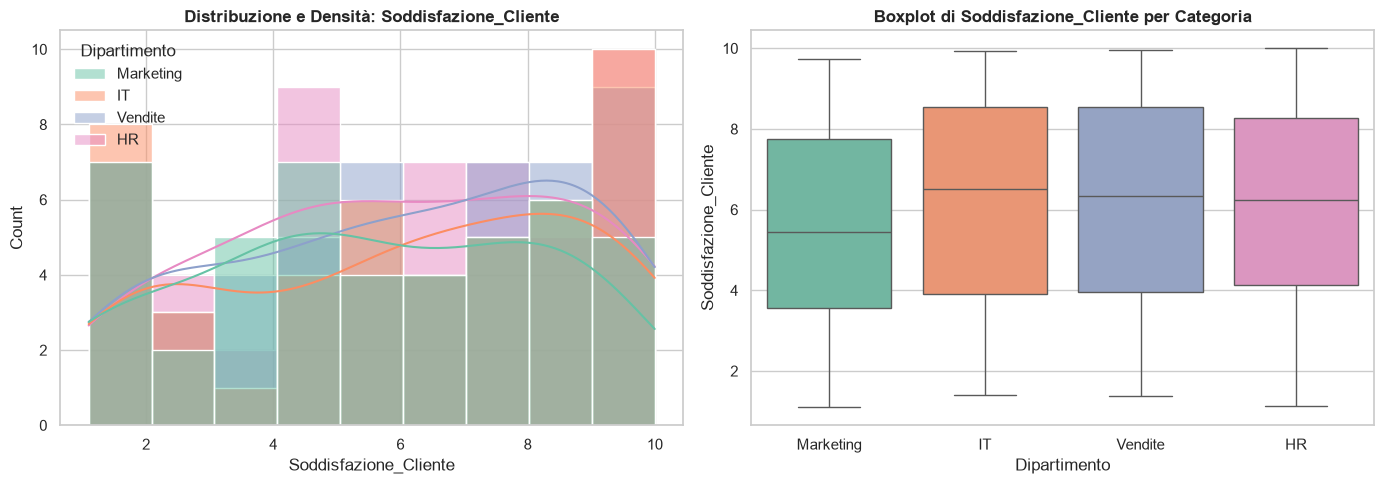

--- Generazione Heatmap di Correlazione ---


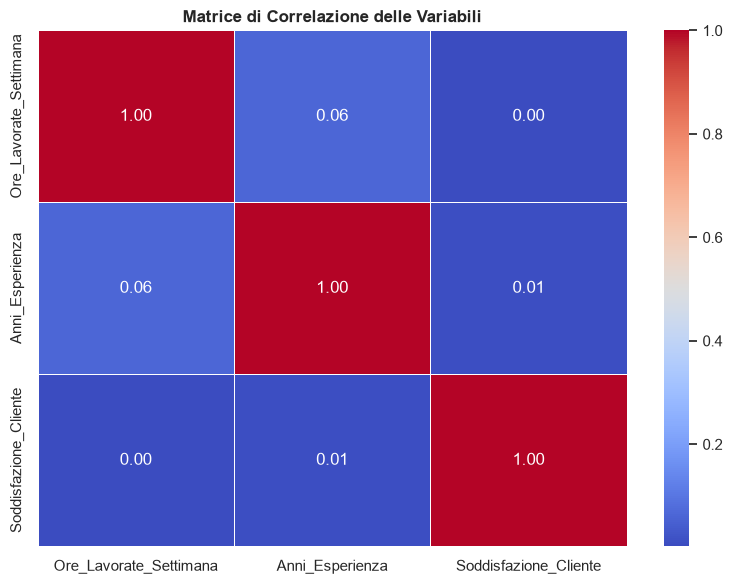

In [13]:
import pandas as pd     # Importa la libreria Pandas per la gestione e manipolazione dei DataFrame
import seaborn as sns   # Importa la libreria Seaborn per la visualizzazione statistica avanzata
import matplotlib.pyplot as plt  # Importa Matplotlib per la gestione delle figure e dei layout grafici
import numpy as np      # Importa NumPy per la generazione di dati numerici casuali di supporto

class AdvancedDataVisualizer:
    """
    Classe orientata agli oggetti (OOP) per gestire un dataset e generare 
    visualizzazioni statistiche avanzate utilizzando Seaborn e Matplotlib.
    """
    
    def __init__(self, df):
        """
        Costruttore della classe. Viene eseguito automaticamente quando si istanzia l'oggetto.
        - df: il DataFrame Pandas che vogliamo analizzare.
        """
        # Salva il DataFrame passato come argomento all'interno di un attributo d'istanza 'self.df'
        self.df = df
        
        # Imposta lo stile grafico predefinito di Seaborn su uno schema moderno con griglia chiara
        sns.set_theme(style="whitegrid")
        
    def plot_distribution(self, feature, hue_col=None):
        """
        Crea un grafico combinato con due sotto-pannelli (1 riga, 2 colonne):
        1. Istogramma con curva di densità KDE (Kernel Density Estimation).
        2. Boxplot per analizzare la mediana, la dispersione e identificare gli outlier.
        """
        # Crea una figura di dimensioni 14x5 pollici contenente una griglia di 1 riga e 2 assi (subplots)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # ==========================================
        # 1. ISTOGRAMMA E DENSITÀ (Pannello di sinistra)
        # ==========================================
        sns.histplot(
            data=self.df,          # Dataset di riferimento
            x=feature,             # Variabile numerica di cui studiare la distribuzione
            hue=hue_col,           # Eventuale variabile categorica per suddividere i colori
            kde=True,              # Aggiunge la linea della curva di densità stimata
            ax=axes[0],            # Posiziona il grafico nel primo sotto-asse (indice 0)
            palette="Set2"         # Tavolozza di colori predefinita di Seaborn
        )
        # Imposta il titolo del primo grafico specificando la feature analizzata
        axes[0].set_title(f"Distribuzione e Densità: {feature}", fontsize=12, fontweight='bold')
        
        # ==========================================
        # 2. BOXPLOT STATISTICO (Pannello di destra)
        # ==========================================
        sns.boxplot(
            data=self.df,          # Dataset di riferimento
            x=hue_col,             # Variabile categorica disposta sull'asse X
            y=feature,             # Variabile numerica disposta sull'asse Y
            hue=hue_col,           # Associa la palette alla variabile X per evitare warning nelle nuove versioni di Seaborn
            legend=False,          # Disattiva la legenda ridondante poiché l'asse X mostra già le categorie
            ax=axes[1],            # Posiziona il grafico nel secondo sotto-asse (indice 1)
            palette="Set2"         # Tavolozza di colori coerente con il primo grafico
        )
        # Imposta il titolo del secondo grafico
        axes[1].set_title(f"Boxplot di {feature} per Categoria", fontsize=12, fontweight='bold')
        
        # Ottimizza automaticamente gli spazi tra i grafici per evitare sovrapposizioni di etichette
        plt.tight_layout()
        
        # Mostra a schermo la figura completa generata
        plt.show()
        
    def plot_correlation_heatmap(self):
        """
        Calcola la matrice di correlazione lineare di Pearson tra tutte le variabili numeriche
        del dataset e la rappresenta visivamente tramite una mappa di calore (Heatmap).
        """
        # Crea una nuova figura dedicata per la matrice di correlazione con dimensioni 8x6 pollici
        plt.figure(figsize=(8, 6))
        
        # Seleziona dal DataFrame solo le colonne di tipo numerico escludendo le stringhe/categorie
        numeric_df = self.df.select_dtypes(include=['number'])
        
        # Calcola la matrice di correlazione tra le variabili numeriche
        correlation_matrix = numeric_df.corr()
        
        # Disegna la heatmap basata sulla matrice di correlazione calcolata
        sns.heatmap(
            correlation_matrix,    # Dati della matrice di correlazione
            annot=True,            # Mostra i valori numerici esatti all'interno di ogni cella della heatmap
            fmt=".2f",             # Formatta i numeri decimali mostrando esattamente 2 cifre dopo la virgola
            cmap="coolwarm",       # Schema di colori (blu per correlazione negativa, rosso per positiva)
            linewidths=0.5,        # Aggiunge una sottile linea di separazione bianca tra una cella e l'altra
            cbar=True              # Mostra la barra della scala dei colori (color bar) sul lato destro
        )
        
        # Imposta il titolo della mappa di calore
        plt.title("Matrice di Correlazione delle Variabili", fontsize=12, fontweight='bold')
        
        # Ottimizza il layout grafico della finestra
        plt.tight_layout()
        
        # Mostra a schermo la heatmap
        plt.show()


# ==========================================
# ESEMPIO PRATICO DI UTILIZZO DIDATTICO
# ==========================================

# 1. Impostiamo un seme casuale per garantire che i dati generati siano identici a ogni esecuzione
np.random.seed(42)

# 2. Creiamo un dizionario contenente dati simulati sulle prestazioni di un'azienda
data = {
    'Ore_Lavorate_Settimana': np.random.normal(40, 5, 200),             # 200 valori con media 40 e dev. std. 5
    'Anni_Esperienza': np.random.randint(1, 15, 200),                   # 200 interi casuali tra 1 e 15 anni
    'Soddisfazione_Cliente': np.random.uniform(1.0, 10.0, 200),         # 200 numeri decimali tra 1.0 e 10.0
    'Dipartimento': np.random.choice(['IT', 'Vendite', 'HR', 'Marketing'], 200) # Categorie casuali
}

# 3. Convertiamo il dizionario in un DataFrame ufficiale di Pandas
df_aziendale = pd.DataFrame(data)

# 4. Istanziamo la nostra classe passando il DataFrame appena creato all'oggetto 'visualizer'
visualizer = AdvancedDataVisualizer(df_aziendale)

# 5. Eseguiamo il primo metodo per analizzare la distribuzione della soddisfazione suddivisa per dipartimento
print("--- Generazione Grafico di Distribuzione ---")
visualizer.plot_distribution(feature='Soddisfazione_Cliente', hue_col='Dipartimento')

# 6. Eseguiamo il secondo metodo per visualizzare la matrice di correlazione numerica sotto forma di Heatmap
print("--- Generazione Heatmap di Correlazione ---")
visualizer.plot_correlation_heatmap()